# Rebuild the CFR from saved path data

A CSIGen file can hold the paths of every channel instead of, or next to, the channel frequency response (CFR) `h`. `load_cfr` rebuilds the exact CFR from the paths, without new ray tracing. It needs only NumPy, so this notebook runs without Sionna RT or a GPU. The plot needs matplotlib.

This notebook downloads one file of the sample dataset, rebuilds its CFR, and then computes the CFR for other settings from the same paths.

In [1]:
import os
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "csigen" / "path_data.py").is_file():
            return p
    raise RuntimeError("Cannot find csigen/path_data.py. Use the CSIGen repo root or a folder inside it as the working directory.")


REPO_ROOT = find_repo_root()

from csigen import load_cfr
from csigen.path_data import subcarrier_offsets

## Download one file of the sample dataset

The file holds one sector of the Boston scene at 3.5 GHz, with the paths and the metadata of every channel but without `h` (about 32 MB). The URL names a fixed revision of the dataset, so the file and the outputs below stay the same. The download goes to a temporary file first, so that an interrupted download is not used later.

In [2]:
REVISION = "c4fa85682e8c1f7026e4468740bd3dccccca98c6"
URL = f"https://huggingface.co/datasets/BerkIGuler/ChaSEDatasets/resolve/{REVISION}/runs/urban/boston_1/channel_tx_0.npz"
npz_file = REPO_ROOT / "output" / "sample_dataset" / "urban" / "boston_1" / "channel_tx_0.npz"

if not npz_file.is_file():
    npz_file.parent.mkdir(parents=True, exist_ok=True)
    tmp_file = npz_file.with_suffix(".part")
    urllib.request.urlretrieve(URL, tmp_file)
    os.replace(tmp_file, npz_file)
print(f"{npz_file.relative_to(REPO_ROOT)}: {npz_file.stat().st_size / 1e6:.1f} MB on disk")

output/sample_dataset/urban/boston_1/channel_tx_0.npz: 32.4 MB on disk


## What the file holds

The file holds the path arrays (`paths_*`) and the metadata, with per-channel path statistics in `path_stats`. The CFR `h` was removed after generation to keep the shared files small. The arrays `shape` and `dtype` record the shape and the type of the removed `h`, and the metadata still records `cfr_saved: True`.

In [3]:
with np.load(npz_file, allow_pickle=True) as z:
    arrays = [k for k in z.files if k != "metadata"]
    has_h = "h" in z.files
    removed_shape, removed_dtype = z["shape"], z["dtype"]
    meta = z["metadata"].item()

stats = meta["path_stats"]
num_paths = stats["num_paths"]
print("arrays:", arrays)
print("h in the file:", has_h, "| cfr_saved in the metadata:", meta["cfr_saved"])
print("shape and dtype of the removed h:", removed_shape, removed_dtype)
print("CFR axes:", meta["cfr_axes"])
print("CFR parameters:", meta["cfr_params"])
print(f"channels: {len(num_paths)}, paths: {num_paths.sum()} in total, median {np.median(num_paths):.0f} per channel")
print(f"strongest path carries {np.median(stats['dominant_power_fraction']):.0%} of the path power (median over the channels)")

arrays: ['shape', 'dtype', 'paths_offsets', 'paths_a', 'paths_tau', 'paths_doppler', 'paths_theta_t', 'paths_phi_t', 'paths_theta_r', 'paths_phi_r', 'paths_interactions']
h in the file: False | cfr_saved in the metadata: True
shape and dtype of the removed h: [6976    1    1   32   14   32] complex64
CFR axes: ['rx', 'rx_ant', 'tx', 'tx_ant', 'ofdm_symbol', 'subcarrier']
CFR parameters: {'carrier_frequency': 3500000000.0, 'num_subcarriers': 32, 'num_ofdm_symbols': 14, 'subcarrier_spacing': 30000.0, 'normalize_delays': False, 'normalize': False}
channels: 6976, paths: 117873 in total, median 13 per channel
strongest path carries 84% of the path power (median over the channels)


## Rebuild the exact CFR

Without arguments, `load_cfr` rebuilds the CFR with the settings of the run. For a file that still holds `h`, the result is equal to `h` bit for bit. The full CFR of this file takes 800 MB, and the computation needs a little over 1 GB of memory at its peak. The next cells use one OFDM symbol, which needs much less.

In [4]:
h = load_cfr(npz_file)
print("shape:", h.shape, h.dtype)
print(f"size in memory: {h.nbytes / 1e6:.0f} MB, from {npz_file.stat().st_size / 1e6:.1f} MB on disk")
del h  # free the memory for the next cells

shape: (6976, 1, 1, 32, 14, 32) complex64
size in memory: 800 MB, from 32.4 MB on disk


## Other settings from the same paths

The arguments of `load_cfr` change the CFR without new ray tracing.

- `max_paths=1` keeps only the strongest path of each channel.
- `num_subcarriers=128` gives a band four times as wide, with the same subcarrier spacing. The subcarriers are centered on the carrier, so the middle subcarriers of the wide band are the subcarriers of the run.

See `docs/main.pdf` for the other options (other arrays, user velocities, numerology, or only some paths).

In [5]:
params = meta["cfr_params"]
n_run, spacing = params["num_subcarriers"], params["subcarrier_spacing"]
n_wide = 4 * n_run

h_one = load_cfr(npz_file, num_ofdm_symbols=1)
h_strongest = load_cfr(npz_file, num_ofdm_symbols=1, max_paths=1)
h_wide = load_cfr(npz_file, num_ofdm_symbols=1, num_subcarriers=n_wide)

f_run = subcarrier_offsets(n_run, spacing)
f_wide = subcarrier_offsets(n_wide, spacing)
middle = np.isin(f_wide, f_run)  # the subcarriers of the run inside the wide band
print("wide-band CFR:", h_wide.shape)
print("middle subcarriers of the wide band equal the CFR of the run:", np.array_equal(h_wide[..., middle], h_one))

wide-band CFR: (6976, 1, 1, 32, 1, 128)
middle subcarriers of the wide band equal the CFR of the run: True


## Plot one channel

The plot shows the magnitude of the CFR of the channel with the most paths, at the first BS antenna. Its paths arrive with different delays, so the CFR fades across the band. The strongest path alone gives a flat response. The wide band shows more of the fading pattern.

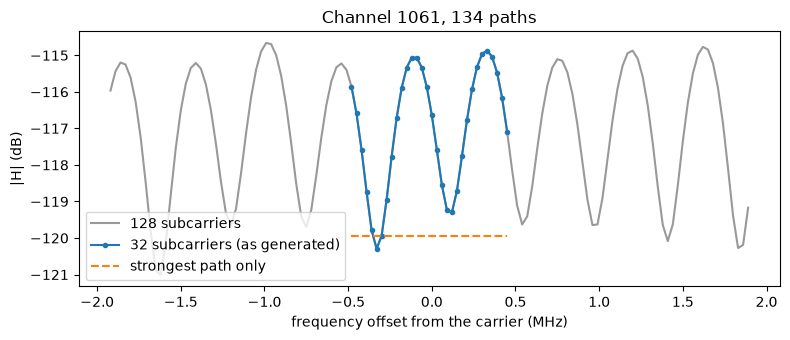

In [6]:
ch = int(np.argmax(num_paths))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f_wide / 1e6, 20 * np.log10(np.abs(h_wide[ch, 0, 0, 0, 0, :])), label=f"{n_wide} subcarriers", color="0.6")
ax.plot(f_run / 1e6, 20 * np.log10(np.abs(h_one[ch, 0, 0, 0, 0, :])), "o-", ms=3, label=f"{n_run} subcarriers (as generated)")
ax.plot(f_run / 1e6, 20 * np.log10(np.abs(h_strongest[ch, 0, 0, 0, 0, :])), "--", label="strongest path only")
ax.set_xlabel("frequency offset from the carrier (MHz)")
ax.set_ylabel("|H| (dB)")
ax.set_title(f"Channel {ch}, {num_paths[ch]} paths")
ax.legend()
fig.tight_layout()
plt.show()